# Chapitre 3 - Cours 1 : Journaux append-only et index de hachage

Ce notebook ouvre le chapitre *Storage and Retrieval* par le point de vue de la base de
données : comment ranger les données qu'on lui confie, et comment les retrouver ? Il
couvre le début de la section *Data Structures That Power Your Database* et la
sous-section *Hash Indexes* : la base « bash » en deux fonctions, la notion d'index et
son coût, l'index de hachage en mémoire à la Bitcask, les segments, leur fusion et leur
compaction, et les détails qui font un vrai moteur (suppressions, reprise après panne,
écritures partielles, concurrence).

**Plan.**

1. La base de données la plus simple du monde : un fichier où l'on ajoute des lignes.
2. Qu'est-ce qu'un index ? Le compromis fondamental lecture contre écriture.
3. Un index de hachage en mémoire au-dessus du journal.
4. Segments, fusion et compaction : récupérer l'espace des valeurs écrasées.
5. Ce qui fait un vrai moteur : format binaire, suppressions, pannes, concurrence.
6. Pourquoi ajouter plutôt que modifier en place ? Et les limites de l'index de hachage.

In [1]:
import os
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
WORK = tempfile.mkdtemp(prefix="ddia_stockage_")

## 1. La base de données la plus simple du monde (section *Data Structures That Power Your Database*)

**Le problème.** Une base de données ne fait, au fond, que deux choses : **ranger** ce
qu'on lui donne et le **rendre** quand on le redemande. Le livre part d'une base
clé-valeur écrite en deux fonctions bash : `db_set clé valeur` ajoute la ligne
`clé,valeur` à la fin d'un fichier, `db_get clé` parcourt le fichier et renvoie la
**dernière** valeur vue pour cette clé (d'où le `tail -n 1`).

En voici la traduction Python (`S.BashDB`). Mettre à jour une clé n'efface rien :
l'ancienne ligne reste, la nouvelle s'ajoute à la fin, et c'est l'ordre du fichier qui
dit laquelle est la plus récente.

In [2]:
db = S.BashDB(os.path.join(WORK, "database"))
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay"]}')
db.set("69", '{"ville":"Lyon","musées":["Confluences"]}')
db.set("75", '{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}')
print("db_get 75 ->", db.get("75"))
print("\ncontenu du fichier :")
print(open(db.path, encoding="utf-8").read())

db_get 75 -> {"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}

contenu du fichier :
75,{"ville":"Paris","musées":["Louvre","Orsay"]}
69,{"ville":"Lyon","musées":["Confluences"]}
75,{"ville":"Paris","musées":["Louvre","Orsay","Quai Branly"]}



Ce fichier est un **journal** (*log*) au sens du livre : une suite d'enregistrements à
laquelle on ne fait **qu'ajouter**. Rien à voir avec les journaux applicatifs lisibles
par un humain : un journal de base de données est souvent binaire et à usage interne.

**Mesurons** les deux opérations. Écrire est très rapide (un ajout en fin de fichier,
sans rien relire) ; lire oblige à parcourir **tout** le fichier : la recherche coûte
$O(n)$ pour $n$ enregistrements. On compte les octets lus (mesure exacte et
reproductible) et on chronomètre (mesure indicative, qui dépend de la machine).

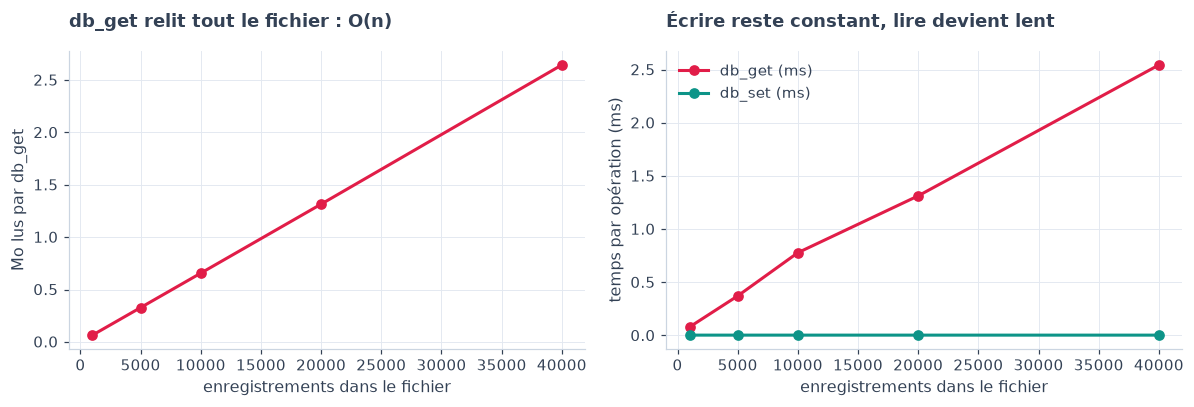

,enregistrements,taille_Mo,us_par_set,ms_par_get,octets_lus_par_get
0,1000,0.065,3.321,0.080,6.478e+04
1,5000,0.328,3.299,0.372,3.277e+05
2,10000,0.657,3.318,0.778,6.566e+05
3,20000,1.315,3.287,1.313,1.315e+06
4,40000,2.644,3.303,2.544,2.644e+06


In [3]:
rows = []
db = S.BashDB(os.path.join(WORK, "bash_perf"))
n_done = 0
for n in [1_000, 5_000, 10_000, 20_000, 40_000]:
    t0 = time.perf_counter()
    for i in range(n_done, n):
        db.set(str(i % (n // 2 + 1)), S.kv_value(i, size=60))
    t_set = (time.perf_counter() - t0) / (n - n_done)
    n_done = n
    db.bytes_scanned = 0
    t0 = time.perf_counter()
    for k in range(5):
        db.get(str(k * 7))
    t_get = (time.perf_counter() - t0) / 5
    rows.append(dict(enregistrements=n, taille_Mo=db.size() / 1e6, us_par_set=t_set * 1e6,
                     ms_par_get=t_get * 1e3, octets_lus_par_get=db.bytes_scanned / 5))
bash = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(bash.enregistrements, bash.octets_lus_par_get / 1e6, "o-", color=ROSE)
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("Mo lus par db_get")
ax.set_title("db_get relit tout le fichier : O(n)")
ax = axes[1]
ax.plot(bash.enregistrements, bash.ms_par_get, "o-", color=ROSE, label="db_get (ms)")
ax.plot(bash.enregistrements, bash.us_par_set / 1e3, "o-", color=TEAL, label="db_set (ms)")
ax.set_xlabel("enregistrements dans le fichier"); ax.set_ylabel("temps par opération (ms)")
ax.set_title("Écrire reste constant, lire devient lent")
ax.legend()
finish(fig)
plt.show()
bash

Le nombre d'octets lus par `db_get` est exactement la taille du fichier : doubler les
données double le coût d'une lecture. `db_set`, lui, garde un coût constant (quelques
microsecondes, essentiellement l'ouverture du fichier). Un vrai moteur fondé sur un
journal doit en plus gérer les écritures concurrentes, récupérer l'espace des vieilles
versions et survivre aux enregistrements à moitié écrits lors d'une panne : nous y
viendrons en section 5.

> **À retenir.** Ajouter en fin de fichier est l'écriture la plus simple et la plus
> rapide possible. Sans structure supplémentaire, la lecture coûte $O(n)$ : il faut un
> **index**.

## 2. Qu'est-ce qu'un index ? (section *Data Structures That Power Your Database*)

**Définition.** Un index est une structure **supplémentaire, dérivée** des données
primaires, qui sert de panneau indicateur : il dit où trouver ce qu'on cherche. On peut
en ajouter ou en retirer sans changer le **contenu** de la base, seulement la vitesse des
requêtes. Si l'on veut chercher les mêmes données de plusieurs façons, il faut plusieurs
index.

**Le compromis.** Chaque index doit être mis à jour à **chaque écriture**. Un bon index
accélère les lectures, mais tout index coûte de l'espace et ralentit les écritures. C'est
pourquoi les bases n'indexent pas tout par défaut : c'est à vous, qui connaissez les
requêtes de l'application, de choisir.

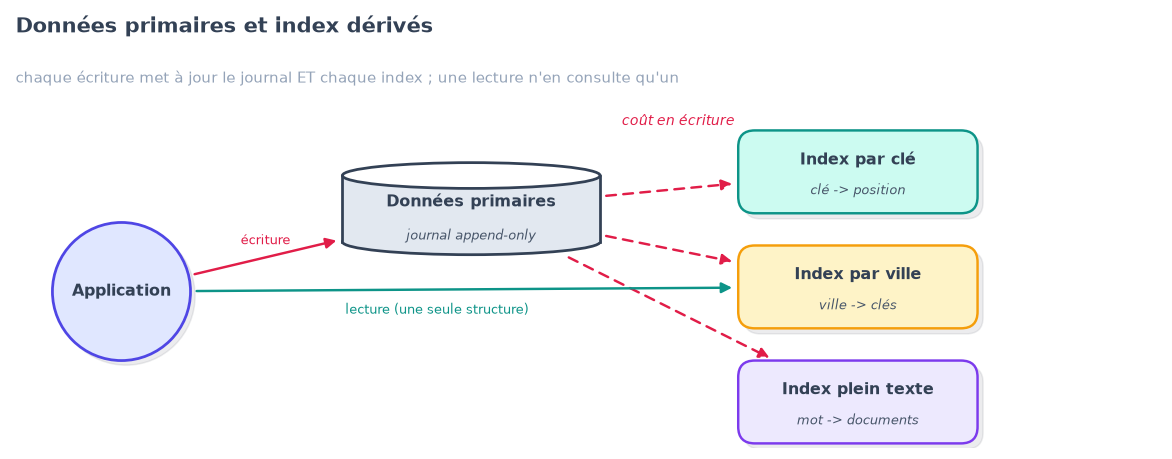

In [4]:
d = Diagram(12.5, 3.8, title="Données primaires et index dérivés",
            subtitle="chaque écriture met à jour le journal ET chaque index ; une lecture n'en consulte qu'un")
d.box("app", 1.2, 1.7, "Application", kind="user", w=1.5, color=INDIGO)
d.box("log", 5.0, 2.6, "Données primaires", sub="journal append-only", color=SLATE, kind="db", w=2.8, h=1.0)
d.box("i1", 9.2, 3.0, "Index par clé", sub="clé -> position", color=TEAL, w=2.6)
d.box("i2", 9.2, 1.75, "Index par ville", sub="ville -> clés", color=AMBER, w=2.6)
d.box("i3", 9.2, 0.5, "Index plein texte", sub="mot -> documents", color=VIOLET, w=2.6)
d.arrow("app", "log", "écriture", color=ROSE)
for i in ("i1", "i2", "i3"):
    d.arrow("log", i, style="dashed", color=ROSE)
d.arrow("app", "i2", "lecture (une seule structure)", color=TEAL, label_pos=0.45, label_offset=(0, -0.22))
d.note(7.25, 3.55, "coût en écriture", color=ROSE)
d.show()

**Mesure.** Le coût d'une écriture croît avec le nombre d'index à maintenir. Simulons des
index en mémoire (des dictionnaires) sur une table de clients et chronométrons 20 000
insertions avec 0 à 6 index.

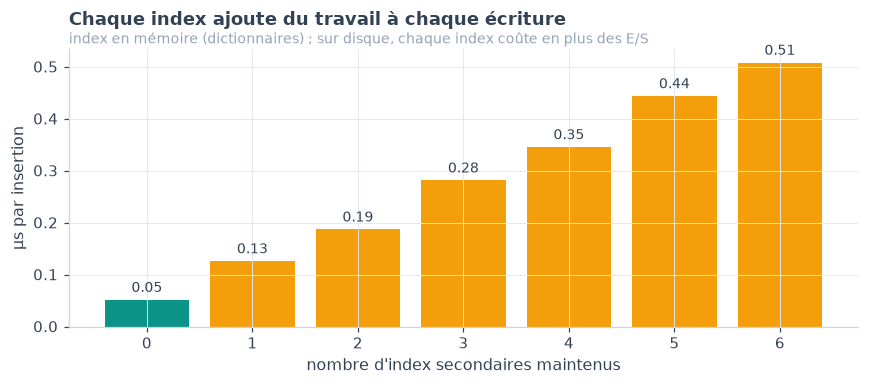

In [5]:
rng = np.random.default_rng(0)
N = 20_000
clients = [dict(id=i, ville=f"v{rng.integers(50)}", age=int(rng.integers(18, 90)),
                nom=f"nom{rng.integers(5000)}", segment=int(rng.integers(5)),
                code=f"c{rng.integers(10**6)}", pays=f"p{rng.integers(30)}") for i in range(N)]
champs = ["ville", "age", "nom", "segment", "code", "pays"]
import gc

mesures = []
for n_index in range(0, 7):
    essais = []
    for _ in range(5):  # on garde le meilleur de 5 essais pour lisser le bruit de mesure
        journal, index = [], {c: {} for c in champs[:n_index]}
        gc.disable()
        t0 = time.perf_counter()
        for row in clients:
            journal.append(row)
            for c, idx in index.items():
                idx.setdefault(row[c], []).append(row["id"])
        essais.append(time.perf_counter() - t0)
        gc.enable()
    mesures.append(dict(index=n_index, us_par_ecriture=min(essais) / N * 1e6))
mes = pd.DataFrame(mesures)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(mes["index"], mes.us_par_ecriture, color=[TEAL] + [AMBER] * 6)
annotate_bars(ax, "{:.2f}")
ax.set_xlabel("nombre d'index secondaires maintenus"); ax.set_ylabel("µs par insertion")
ax.set_title("Chaque index ajoute du travail à chaque écriture")
subtitle(ax, "index en mémoire (dictionnaires) ; sur disque, chaque index coûte en plus des E/S")
plt.tight_layout(); plt.show()

Le coût par insertion augmente à peu près linéairement avec le nombre d'index : avec six
index, une insertion coûte plusieurs fois l'ajout nu au journal. Sur disque, l'effet est
bien plus marqué, car chaque index peut exiger ses propres lectures et écritures de pages
(nous le mesurerons sur PostgreSQL dans le lab).

> **À retenir.** Un index est une structure dérivée qui accélère certaines lectures au
> prix d'écritures plus lentes et d'espace en plus. Choisir ses index, c'est arbitrer
> selon les requêtes réelles de l'application.

## 3. Un index de hachage en mémoire (section *Hash Indexes*)

**Idée.** Gardons le journal tel quel (écritures rapides), mais tenons **en mémoire** une
table de hachage qui associe à chaque clé la **position** (*offset*, en octets) de sa
valeur la plus récente dans le fichier. Écrire = ajouter au fichier **et** mettre à
jour la table ; lire = consulter la table, se positionner (`seek`) et lire une seule
valeur. Si cette partie du fichier est déjà dans le cache du système de fichiers, la
lecture ne fait même aucune E/S disque.

C'est le principe de **Bitcask**, le moteur par défaut de la base Riak :
performances excellentes tant que toutes les clés tiennent en RAM, ce qui convient bien
à des clés peu nombreuses souvent mises à jour (par exemple un compteur de lectures par
URL de vidéo).

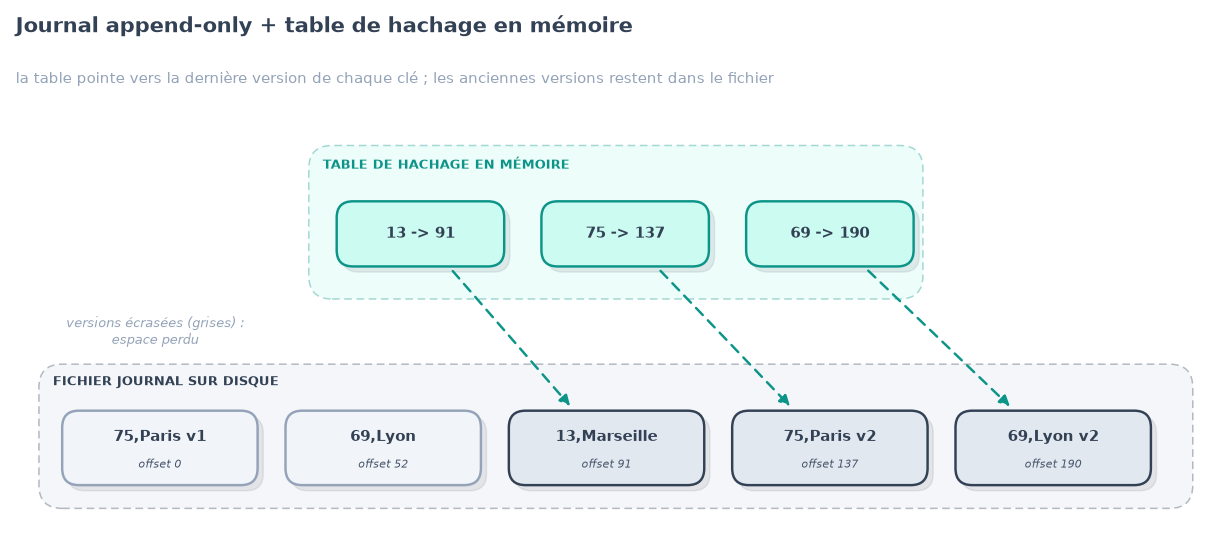

In [6]:
d = Diagram(13, 4.6, title="Journal append-only + table de hachage en mémoire",
            subtitle="la table pointe vers la dernière version de chaque clé ; les anciennes versions restent dans le fichier")
d.group(0.3, 0.2, 12.7, 1.75, "fichier journal sur disque", color=SLATE)
recs = [("75", "Paris v1", 0), ("69", "Lyon", 52), ("13", "Marseille", 91), ("75", "Paris v2", 137),
        ("69", "Lyon v2", 190)]
for j, (k, v, off) in enumerate(recs):
    x = 1.6 + j * 2.4
    old = (k == "75" and j == 0) or (k == "69" and j == 1)
    d.box(f"r{j}", x, 0.85, f"{k},{v}", sub=f"offset {off}", color=GRAY if old else SLATE, w=2.1, h=0.8,
          fontsize=9.5)
d.group(3.2, 2.45, 9.8, 4.1, "table de hachage en mémoire", color=TEAL)
for j, (k, tgt) in enumerate([("13", 2), ("75", 3), ("69", 4)]):
    x = 4.4 + j * 2.2
    d.box(f"h{k}", x, 3.15, f"{k} -> {recs[tgt][2]}", color=TEAL, w=1.8, h=0.7, fontsize=9.5)
    d.arrow(f"h{k}", f"r{tgt}", color=TEAL, style="dashed")
d.note(1.55, 2.1, "versions écrasées (grises) :\nespace perdu", color=GRAY, fontsize=8.5)
d.show()

`S.HashIndexStore` implémente ce moteur avec de vrais fichiers. Chaque enregistrement
est encodé en binaire (section 5) ; l'index associe `clé -> (segment, offset, taille)`.
Comparons le coût d'une lecture avec celui de la base bash, en octets lus.

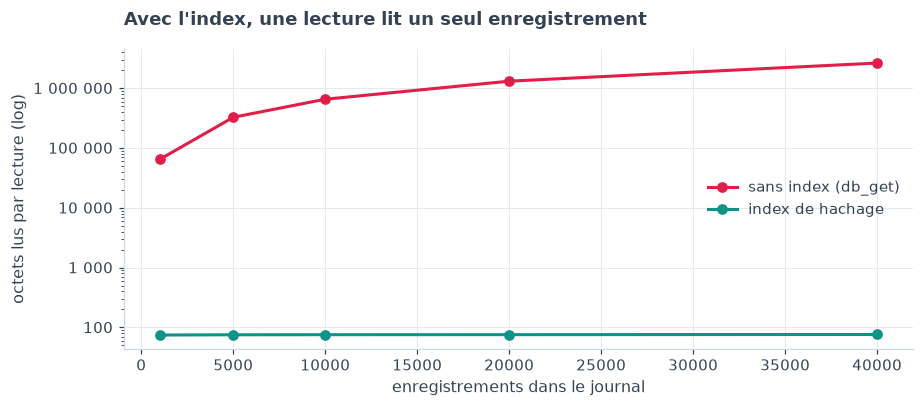

,enregistrements,octets_lus_par_get,us_par_get,cles_en_memoire
0,1000,74.780,1.440,501
1,5000,75.556,3.491,2501
2,10000,75.778,3.454,5001
3,20000,75.889,3.502,10001
4,40000,76.445,3.506,20001


In [7]:
rows = []
for n in [1_000, 5_000, 10_000, 20_000, 40_000]:
    st = S.HashIndexStore(os.path.join(WORK, f"hash_{n}"), segment_bytes=1 << 30)
    for i in range(n):
        st.put(str(i % (n // 2 + 1)), S.kv_value(i, size=60))
    t0 = time.perf_counter()
    for k in range(200):
        st.get(str(k * 7))
    t_get = (time.perf_counter() - t0) / 200
    rows.append(dict(enregistrements=n, octets_lus_par_get=st.live_bytes() / len(st.index),
                     us_par_get=t_get * 1e6, cles_en_memoire=len(st.index)))
    st.close()
hidx = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(bash.enregistrements, bash.octets_lus_par_get, "o-", color=ROSE, label="sans index (db_get)")
ax.plot(hidx.enregistrements, hidx.octets_lus_par_get, "o-", color=TEAL, label="index de hachage")
ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xlabel("enregistrements dans le journal"); ax.set_ylabel("octets lus par lecture (log)")
ax.set_title("Avec l'index, une lecture lit un seul enregistrement")
ax.legend()
plt.tight_layout(); plt.show()
hidx

La lecture passe d'un parcours de plusieurs mégaoctets à la lecture d'un seul
enregistrement (environ 70 octets ici), quelle que soit la taille du journal : le coût
est $O(1)$. Le prix : la table de hachage contient **toutes** les clés et doit tenir en
mémoire (colonne `cles_en_memoire`).

> **À retenir.** Un index de hachage en mémoire sur un journal append-only donne des
> écritures séquentielles rapides et des lectures en une seule E/S. Sa contrainte
> principale : toutes les clés doivent tenir en RAM.